# E-commerce conversion analysis and checkout experiment proposal

**GA4 obfuscated sample e-commerce data | November 2020–January 2021**

This notebook investigates device differences, audits funnel measurement, and develops a hypothetical experiment to clarify ground-shipping delivery dates. It combines SQL-derived session data with Python summaries, user-level bootstrap intervals, and planning scenarios.

### Main findings

- **Overall purchase conversion:** 4,848 purchasing sessions out of 360,129 sessions (1.35%).
- **Device evidence:** the mobile–desktop gap is +0.0776 percentage points; the user-bootstrap interval includes zero. Separate week and medium adjustments change the estimate very little.
- **Measurement issue:** raw mobile/desktop cart events are absent on November 2–15 and November 21–24. We cannot attribute this to a specific cause.
- **Restricted funnel:** December–January contains 2,302 complete recorded view → cart → checkout → purchase sequences. This is not a count of every legitimate purchase journey.
- **Action:** validate tracking and consider testing delivery-date information. Revenue and sample-size calculations are hypothetical, not forecasts or experimental results.

### Contents

1. [Setup and metric definitions](#setup)
2. [Baseline and repeated users](#baseline)
3. [Device comparison and bootstrap uncertainty](#device)
4. [Week and acquisition-medium sensitivity](#adjustments)
5. [Stage reach and checkout co-occurrence](#checkout)
6. [Time patterns and measurement audit](#audit)
7. [December–January and the ordered funnel](#ordered)
8. [Illustrative revenue scenarios](#revenue)
9. [Findings and experiment proposal](#experiment)
10. [Sample size and duration](#power)
11. [Conclusions and next steps](#conclusion)
12. [SQL provenance](#sql)

**Reading note:** existing calculations and saved tables/charts are retained. Explanatory text summarizes this dataset; it will need review if the input data changes.

<a id="setup"></a>

## 1. Setup and metric definitions

Place `Sessions.csv` in the notebook's working directory, select a Python kernel, and run cells from top to bottom. Required packages are `pandas`, `numpy`, `matplotlib`, and `statsmodels`. The two bootstrap loops may take a while because each performs 2,000 repetitions.

The input is a SQL export with one row per `(user_pseudo_id, ga_session_id)` pair. IDs are read as strings to avoid treating identifiers as measurements; `session_date` and `week_start` are parsed as dates. `head()` displays five rows without removing the rest.

| Term | Definition / denominator |
|---|---|
| Session purchase conversion | Purchasing sessions divided by all sessions in the selected population |
| Stage reach | Sessions with a stage flag of 1 divided by all selected sessions |
| Purchase among checkout | Sessions with both checkout and purchase divided by checkout sessions; event order is not established |
| Strict ordered progression | Sessions reaching the next stage after the preceding stages in timestamp order |
| Percentage-point gap | Difference between two percentages; 1.39% − 1.31% is about 0.08 pp, not 8% |
| AOV | Revenue per eligible deduplicated order; distinct from revenue per purchasing session |

All-device baselines include tablets. Device comparisons and checkout analyses use mobile and desktop. A `user_pseudo_id` is an observed identifier, not a guaranteed unique person or a guaranteed cross-device identity.

In [1]:
import pandas as pd

sessions = pd.read_csv(
    "Sessions.csv",
    dtype={
        "user_pseudo_id": "string",
        "ga_session_id": "string"
    },
    parse_dates=["session_date", "week_start"]
)

sessions.head()

,user_pseudo_id,ga_session_id,session_date,week_start,device_category,first_user_source,first_user_medium,event_count,viewed_product,added_to_cart,began_checkout,purchased,purchase_session_flag
0,1071294.7906243682,7554077481,2020-12-27,2020-12-21,desktop,(direct),(none),3,False,False,False,False,0
1,1092569.5237147259,696625214,2020-12-27,2020-12-21,mobile,(direct),(none),7,False,False,False,False,0
2,1094213.8082866113,2299345606,2020-12-27,2020-12-21,desktop,google,cpc,7,False,False,False,False,0
3,1112735.0039619329,5570863366,2020-12-27,2020-12-21,desktop,google,organic,4,False,False,False,False,0
4,1171931.3003166765,5154152746,2020-12-27,2020-12-21,desktop,(data deleted),(data deleted),4,False,False,False,False,0


In [2]:
sessions.columns.tolist()

['user_pseudo_id',
 'ga_session_id',
 'session_date',
 'week_start',
 'device_category',
 'first_user_source',
 'first_user_medium',
 'event_count',
 'viewed_product',
 'added_to_cart',
 'began_checkout',
 'purchased',
 'purchase_session_flag']

<a id="baseline"></a>

## 2. Baseline and repeated users

Reproduce the SQL totals before analyzing differences. Summing a binary purchase flag counts purchasing sessions; averaging it gives the purchase proportion. Multiple orders within a session still contribute only one purchasing session.

In [3]:
total_sessions = len(sessions)

purchase_sessions = sessions["purchase_session_flag"].sum()

purchase_conversion_pct = (
    purchase_sessions / total_sessions
) * 100

print("Total sessions:", total_sessions)
print("Purchasing sessions:", purchase_sessions)
print("Purchase conversion (%):", round(purchase_conversion_pct, 2))

Total sessions: 360129
Purchasing sessions: 4848
Purchase conversion (%): 1.35


In [4]:
device_summary = sessions.groupby("device_category").agg(
    total_sessions=("purchase_session_flag", "size"),
    purchase_sessions=("purchase_session_flag", "sum"),
    conversion_rate=("purchase_session_flag", "mean")
)

device_summary["conversion_pct"] = (
    device_summary["conversion_rate"] * 100
)

device_summary

,total_sessions,purchase_sessions,conversion_rate,conversion_pct
device_category,,,,
desktop,208942,2749,0.013157,1.315676
mobile,143185,1995,0.013933,1.393302
tablet,8002,104,0.012997,1.299675


### Why repeated users matter

`groupby(...).size()` counts sessions per user. Of 270,154 observed users, 47,364 (17.53%) have multiple sessions, with a maximum of 12. Sessions from one user may be related, so later uncertainty estimates resample whole users rather than individual sessions.

In [5]:
sessions_per_user = sessions.groupby("user_pseudo_id").size()

total_users = len(sessions_per_user)

repeat_users = (sessions_per_user > 1).sum()

repeat_user_pct = repeat_users/total_users * 100

print("Unique users:", total_users)
print("Users with multiple sessions:", repeat_users)
print("Percentage with multiple sessions:", round(repeat_user_pct, 2))
print("Most sessions for one user:", sessions_per_user.max())


Unique users: 270154
Users with multiple sessions: 47364
Percentage with multiple sessions: 17.53
Most sessions for one user: 12


<a id="device"></a>

## 3. Device comparison and bootstrap uncertainty

**Question:** how uncertain is the mobile-minus-desktop session conversion difference?

First aggregate counts per user and device. `reset_index()` makes group labels ordinary columns. `pivot()` then puts one user on each row with separate device-count columns. Missing user–device combinations become zero counts, not missing observations. We retain counts so the statistic remains a ratio of total purchasing sessions to total sessions—not an average of individual user conversion rates.

In [6]:
user_device_summary = (
    sessions.groupby(["user_pseudo_id", "device_category"])
    .agg(
        session_count=("purchase_session_flag", "size"),
        purchase_session_count=("purchase_session_flag", "sum")
    )
    .reset_index()
)

user_device_summary.head()

,user_pseudo_id,device_category,session_count,purchase_session_count
0,10001363.4360935308,desktop,1,0
1,1000223163.8035209215,mobile,1,0
2,1000299.7413851356,desktop,1,0
3,1000300.3223254235,desktop,2,0
4,10003031.4607645453,desktop,1,0


In [7]:
user_counts = (
    user_device_summary.pivot(
        index="user_pseudo_id",
        columns="device_category",
        values=["session_count", "purchase_session_count"]
    )
    .fillna(0)
    .astype(int)
)

user_counts.head()

session_count               purchase_session_count  \
device_category             desktop mobile tablet                desktop   
user_pseudo_id                                                             
10001363.4360935308               1      0      0                      0   
1000223163.8035209215             0      1      0                      0   
1000299.7413851356                1      0      0                      0   
1000300.3223254235                2      0      0                      0   
10003031.4607645453               1      0      0                      0   

                                     
device_category       mobile tablet  
user_pseudo_id                       
10001363.4360935308        0      0  
1000223163.8035209215      0      0  
1000299.7413851356         0      0  
1000300.3223254235         0      0  
10003031.4607645453        0      0

### Resampling method

Each repetition draws **270,154 user rows with replacement**. Repeated selections contribute their counts repeatedly; users not selected contribute zero. The same selection is used for both device rates, preserving any within-identifier device relationship. Tablet-only users remain in the sampling population and contribute zero to these two device totals.

For user counts $Y$ (purchasing sessions), $N$ (sessions), and bootstrap selection multiplicities $w_i$:

$$\Delta^*=\frac{\sum_i w_iY_{iM}}{\sum_i w_iN_{iM}}-\frac{\sum_i w_iY_{iD}}{\sum_i w_iN_{iD}}.$$

`rng.integers()` selects row positions, `counts[sampled_indices]` retrieves them, and `sum(axis=0)` sums down each column. The seed makes the random procedure reproducible. The 2,000 repetitions approximate the distribution; they are not 2,000 new observed datasets.

In [8]:
import numpy as np

# Each row represents one user.
# Columns: mobile sessions, mobile purchases,
#          desktop sessions, desktop purchases.
counts = user_counts[
    [
        ("session_count", "mobile"),
        ("purchase_session_count", "mobile"),
        ("session_count", "desktop"),
        ("purchase_session_count", "desktop")
    ]
].to_numpy()

number_of_users = len(counts)
number_of_repetitions = 2000

rng = np.random.default_rng(42)

bootstrap_differences = np.empty(number_of_repetitions)

for b in range(number_of_repetitions):
    sampled_indices = rng.integers(
        0,
        number_of_users,
        size=number_of_users
    )

    totals = counts[sampled_indices].sum(axis=0)

    mobile_rate = totals[1] / totals[0]
    desktop_rate = totals[3] / totals[2]

    bootstrap_differences[b] = mobile_rate - desktop_rate

### Standard error and percentile interval

The standard deviation of the bootstrap differences estimates the statistic's standard error (`ddof=1`). The 2.5th and 97.5th percentiles form an approximate 95% percentile-bootstrap interval. Multiplying a proportion difference by 100 expresses it in percentage points.

This inference assumes sufficiently independent, representative user clusters. It does not correct obfuscation, tracking errors, temporal dependence across users, or confounding. The exact recorded-data difference itself does not require a confidence interval; the interval concerns generalization beyond these observations.

In [9]:
# Observed difference using every user once.
original_totals = counts.sum(axis=0)

observed_difference = (
    original_totals[1] / original_totals[0]
    - original_totals[3] / original_totals[2]
)

# Bootstrap uncertainty estimates.
standard_error = bootstrap_differences.std(ddof=1)

lower, upper = np.percentile(
    bootstrap_differences,
    [2.5, 97.5]
)

print(
    f"Observed difference: {observed_difference * 100:.4f} percentage points"
)
print(
    f"Bootstrap standard error: {standard_error * 100:.4f} percentage points"
)
print(
    f"95% bootstrap interval: [{lower * 100:.4f}, {upper * 100:.4f}] percentage points"
)

Observed difference: 0.0776 percentage points
Bootstrap standard error: 0.0424 percentage points
95% bootstrap interval: [-0.0051, 0.1610] percentage points


**Interpretation:** mobile leads by **0.0776 pp**, with standard error **0.0424 pp** and interval **[−0.0051, +0.1610] pp**. The interval includes zero, so the data do not clearly distinguish a population device gap from zero under these assumptions. This is neither proof of equality nor evidence that device choice causes conversion.

<a id="adjustments"></a>

## 4. Sensitivity to week and first-user medium

### 4.1 Weekly conversion

Calculate conversion within each week and device before combining weeks. A shared time pattern may affect both devices. The row labeled October 26 contains only November 1 within the data window; the chart omits that partial week, while the adjustment retains its actual traffic.

In [10]:
weekly_device_summary = (
    sessions.groupby(["week_start", "device_category"])
    .agg(
        total_sessions=("purchase_session_flag", "size"),
        purchase_sessions=("purchase_session_flag", "sum"),
        conversion_rate=("purchase_session_flag", "mean")
    )
    .reset_index()
)

weekly_device_summary["conversion_pct"] = (
    weekly_device_summary["conversion_rate"] * 100
)

weekly_conversion = weekly_device_summary.pivot(
    index="week_start",
    columns="device_category",
    values="conversion_pct"
)

weekly_conversion["mobile_minus_desktop_pp"] = (
    weekly_conversion["mobile"] - weekly_conversion["desktop"]
)

weekly_conversion

device_category,desktop,mobile,tablet,mobile_minus_desktop_pp
week_start,,,,
2020-10-26,0.589005,0.382044,0.000000,-0.206961
2020-11-02,1.005339,0.958945,1.436266,-0.046394
2020-11-09,1.530690,1.555680,0.394477,0.024990
2020-11-16,1.341034,1.623882,0.881834,0.282847
2020-11-23,1.769801,1.929982,2.698145,0.160181
2020-11-30,1.884915,1.911035,2.000000,0.026120
2020-12-07,2.050626,1.940534,1.410106,-0.110092
2020-12-14,1.599340,1.750300,0.837989,0.150961
2020-12-21,0.937894,1.190476,1.629328,0.252582


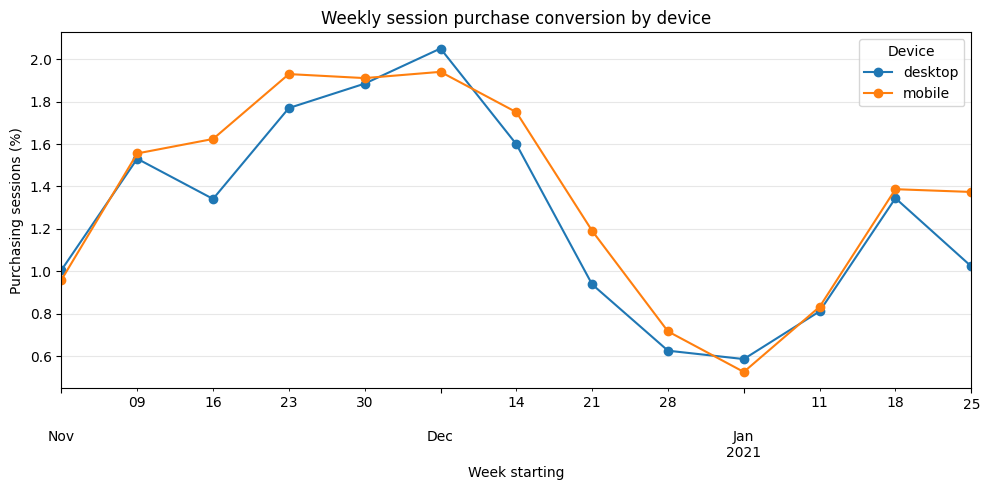

In [11]:
import matplotlib.pyplot as plt

# Exclude the first, partial week from this visualization.
full_weeks = weekly_conversion.iloc[1:]

ax = full_weeks[["desktop", "mobile"]].plot(
    figsize=(10, 5),
    marker="o"
)

ax.set_title("Weekly session purchase conversion by device")
ax.set_xlabel("Week starting")
ax.set_ylabel("Purchasing sessions (%)")
ax.legend(title="Device")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Standardize the weekly traffic mix

An ordinary device rate implicitly weights weeks by that device's own session counts. Here both devices receive a common weight $a_w$: the week's share of combined mobile-plus-desktop sessions. The adjusted difference is $\sum_w a_w(p_{Mw}-p_{Dw})$.

This changes each week's contribution, not its observed rate. It asks how devices compare under the same weekly traffic distribution. Pandas aligns the multiplication by week labels.

In [12]:
# Session counts for each week and device.
weekly_sessions = weekly_device_summary.pivot(
    index="week_start",
    columns="device_category",
    values="total_sessions"
)

# Each week's combined mobile and desktop traffic.
combined_sessions = (
    weekly_sessions["mobile"] + weekly_sessions["desktop"]
)

week_weights = combined_sessions / combined_sessions.sum()

# Apply the same weekly weights to both devices' conversion rates.
adjusted_mobile_pct = (
    weekly_conversion["mobile"] * week_weights
).sum()

adjusted_desktop_pct = (
    weekly_conversion["desktop"] * week_weights
).sum()

adjusted_difference_pp = (
    adjusted_mobile_pct - adjusted_desktop_pct
)

print(f"Week-adjusted mobile conversion: {adjusted_mobile_pct:.4f}%")
print(f"Week-adjusted desktop conversion: {adjusted_desktop_pct:.4f}%")
print(f"Week-adjusted difference: {adjusted_difference_pp:.4f} percentage points")
print(f"Unadjusted difference: {observed_difference * 100:.4f} percentage points")

Week-adjusted mobile conversion: 1.3948%
Week-adjusted desktop conversion: 1.3146%
Week-adjusted difference: 0.0803 percentage points
Unadjusted difference: 0.0776 percentage points


**Result:** the week-adjusted gap is **+0.0803 pp**, compared with **+0.0776 pp** unadjusted. Weekly traffic composition explains little of this observed gap. This is a point estimate; the earlier interval does not apply to it.

### 4.2 First-user acquisition medium

`first_user_medium` describes original acquisition, not necessarily the source of the current session. `dropna=False` keeps missing values visible. Treat `(data deleted)` and `<Other>` as reported categories, not identifiable actionable channels. Their rates cannot tell us which campaign to invest in.

In [13]:
medium_summary = (
    sessions.groupby("first_user_medium", dropna=False)
    .agg(
        total_sessions=("purchase_session_flag", "size"),
        purchase_sessions=("purchase_session_flag", "sum"),
        conversion_rate=("purchase_session_flag", "mean")
    )
    .sort_values("total_sessions", ascending=False)
)

medium_summary["conversion_pct"] = (
    medium_summary["conversion_rate"] * 100
)

medium_summary

,total_sessions,purchase_sessions,conversion_rate,conversion_pct
first_user_medium,,,,
organic,122841,1347,0.010965,1.096539
(none),83459,1079,0.012929,1.292850
referral,63524,1056,0.016624,1.662364
<Other>,52058,506,0.009720,0.971993
(data deleted),22629,707,0.031243,3.124310
cpc,15618,153,0.009796,0.979639


The next table compares both conversion and composition. `transform("sum")` repeats each device's total beside its medium rows. Dividing each row by that total gives the fraction of the device's traffic in that medium.

In [14]:
medium_device_summary = (
    sessions[
        sessions["device_category"].isin(["mobile", "desktop"])
    ]
    .groupby(["first_user_medium", "device_category"], dropna=False)
    .agg(
        total_sessions=("purchase_session_flag", "size"),
        purchase_sessions=("purchase_session_flag", "sum"),
        conversion_rate=("purchase_session_flag", "mean")
    )
    .reset_index()
)

medium_device_summary["conversion_pct"] = (
    medium_device_summary["conversion_rate"] * 100
)

# Total sessions for the corresponding device.
device_totals = (
    medium_device_summary.groupby("device_category")["total_sessions"]
    .transform("sum")
)

medium_device_summary["device_traffic_share_pct"] = (
    100 * medium_device_summary["total_sessions"] / device_totals
)

medium_device_summary

,first_user_medium,device_category,total_sessions,purchase_sessions,conversion_rate,conversion_pct,device_traffic_share_pct
0,(data deleted),desktop,13093,404,0.030856,3.085618,6.266332
1,(data deleted),mobile,9048,287,0.031720,3.171972,6.319098
2,(none),desktop,48651,619,0.012723,1.272327,23.284452
3,(none),mobile,32968,435,0.013195,1.319461,23.024758
4,<Other>,desktop,30171,289,0.009579,0.957873,14.439892
5,<Other>,mobile,20692,203,0.009811,0.981055,14.451234
6,cpc,desktop,9120,98,0.010746,1.074561,4.364848
7,cpc,mobile,6136,52,0.008475,0.847458,4.285365
8,organic,desktop,71068,744,0.010469,1.046885,34.013267
9,organic,mobile,49050,580,0.011825,1.182467,34.256382


Apply the same combined-traffic weighting approach to medium. Every displayed medium has observations on both devices; empty cells would need explicit treatment before standardization.

In [15]:
medium_rates = medium_device_summary.pivot(
    index="first_user_medium",
    columns="device_category",
    values="conversion_pct"
)

medium_sessions = medium_device_summary.pivot(
    index="first_user_medium",
    columns="device_category",
    values="total_sessions"
)

# Each medium's share of combined mobile and desktop sessions.
combined_medium_sessions = (
    medium_sessions["mobile"] + medium_sessions["desktop"]
)

medium_weights = (
    combined_medium_sessions / combined_medium_sessions.sum()
)

# Give each medium the same weight for both devices.
medium_adjusted_mobile_pct = (
    medium_rates["mobile"] * medium_weights
).sum()

medium_adjusted_desktop_pct = (
    medium_rates["desktop"] * medium_weights
).sum()

medium_adjusted_difference_pp = (
    medium_adjusted_mobile_pct - medium_adjusted_desktop_pct
)

print(
    f"Medium-adjusted difference: "
    f"{medium_adjusted_difference_pp:.4f} percentage points"
)
print(
    f"Unadjusted difference: "
    f"{observed_difference * 100:.4f} percentage points"
)

Medium-adjusted difference: 0.0767 percentage points
Unadjusted difference: 0.0776 percentage points


**Result:** the medium-adjusted gap is **+0.0767 pp**. The medium mixes are already very similar. Week and medium are adjusted **separately**, not jointly; neither calculation removes all confounding or supplies an adjusted confidence interval.

<a id="checkout"></a>

## 5. Stage reach and checkout co-occurrence

### 5.1 Stage reach is not an ordered funnel

Sum each binary stage flag to count sessions; average it to obtain the proportion of all sessions reaching that stage. A later-stage flag need not imply an earlier-stage flag, so subtracting these independent totals does not measure sequential abandonment.

In [16]:
stage_columns = [
    "viewed_product",
    "added_to_cart",
    "began_checkout",
    "purchase_session_flag"
]

funnel_summary = pd.DataFrame({
    "sessions_reaching_stage": sessions[stage_columns].sum(),
    "stage_reach_pct": sessions[stage_columns].mean() * 100
})

funnel_summary

,sessions_reaching_stage,stage_reach_pct
viewed_product,77020,21.386781
added_to_cart,15188,4.217378
began_checkout,11106,3.083895
purchase_session_flag,4848,1.346184


In [17]:
device_stage_reach = (
    sessions[
        sessions["device_category"].isin(["mobile", "desktop"])
    ]
    .groupby("device_category")[stage_columns]
    .mean()
    .mul(100)
    .T
)

device_stage_reach["mobile_minus_desktop_pp"] = (
    device_stage_reach["mobile"] - device_stage_reach["desktop"]
)

device_stage_reach

device_category,desktop,mobile,mobile_minus_desktop_pp
viewed_product,21.450450,21.301812,-0.148638
added_to_cart,4.206909,4.244160,0.037251
began_checkout,3.059222,3.124629,0.065407
purchase_session_flag,1.315676,1.393302,0.077626


### 5.2 Purchase among sessions with checkout

Filter to mobile/desktop sessions with `began_checkout == 1`. The numerator counts sessions containing both checkout and purchase; the denominator is checkout sessions. The CSV contains flags, not event timestamps, so this measures co-occurrence rather than proven checkout → purchase ordering.

In [18]:
checkout_sessions = sessions[
    sessions["device_category"].isin(["mobile", "desktop"])
    & (sessions["began_checkout"] == 1)
]

checkout_summary = (
    checkout_sessions.groupby("device_category")
    .agg(
        checkout_sessions=("purchase_session_flag", "size"),
        checkout_sessions_with_purchase=("purchase_session_flag", "sum"),
        purchase_among_checkout_rate=("purchase_session_flag", "mean")
    )
)

checkout_summary["purchase_among_checkout_pct"] = (
    checkout_summary["purchase_among_checkout_rate"] * 100
)

checkout_summary

,checkout_sessions,checkout_sessions_with_purchase,purchase_among_checkout_rate,purchase_among_checkout_pct
device_category,,,,
desktop,6392,2748,0.429912,42.991239
mobile,4474,1993,0.445463,44.546267


### 5.3 User-bootstrap interval for checkout co-occurrence

Prepare the same four-column structure, now using checkout counts and checkout-with-purchase counts. `unstack()` moves device labels into columns. Reindexing to the full original user population keeps users without checkout, who contribute zeros. This preserves the original sampling population while estimating a conditional ratio.

In [19]:
checkout_user_counts = (
    checkout_sessions
    .groupby(["user_pseudo_id", "device_category"])
    .agg(
        checkout_count=("purchase_session_flag", "size"),
        purchase_count=("purchase_session_flag", "sum")
    )
    .unstack("device_category")
    .fillna(0)
)

# Keep the original user population, including users with no checkout.
checkout_user_counts = (
    checkout_user_counts
    .reindex(user_counts.index, fill_value=0)
    .astype(int)
)

checkout_counts = checkout_user_counts[
    [
        ("checkout_count", "mobile"),
        ("purchase_count", "mobile"),
        ("checkout_count", "desktop"),
        ("purchase_count", "desktop")
    ]
].to_numpy()

print(checkout_counts.sum(axis=0))

[4474 1993 6392 2748]


In [20]:
rng = np.random.default_rng(42)

number_of_users = len(checkout_counts)
number_of_repetitions = 2000

checkout_bootstrap_differences = np.empty(number_of_repetitions)

for b in range(number_of_repetitions):
    sampled_indices = rng.integers(
        0,
        number_of_users,
        size=number_of_users
    )

    totals = checkout_counts[sampled_indices].sum(axis=0)

    mobile_rate = totals[1] / totals[0]
    desktop_rate = totals[3] / totals[2]

    checkout_bootstrap_differences[b] = mobile_rate - desktop_rate

# Observed difference using all users.
checkout_totals = checkout_counts.sum(axis=0)

checkout_observed_difference = (
    checkout_totals[1] / checkout_totals[0]
    - checkout_totals[3] / checkout_totals[2]
)

checkout_standard_error = checkout_bootstrap_differences.std(ddof=1)

checkout_lower, checkout_upper = np.percentile(
    checkout_bootstrap_differences,
    [2.5, 97.5]
)

print(
    f"Checkout difference: "
    f"{checkout_observed_difference * 100:.4f} percentage points"
)
print(
    f"Bootstrap standard error: "
    f"{checkout_standard_error * 100:.4f} percentage points"
)
print(
    f"95% bootstrap interval: "
    f"[{checkout_lower * 100:.4f}, {checkout_upper * 100:.4f}] "
    f"percentage points"
)

Checkout difference: 1.5550 percentage points
Bootstrap standard error: 0.9958 percentage points
95% bootstrap interval: [-0.4200, 3.4769] percentage points


**Interpretation:** mobile is **44.55%** versus desktop **42.99%**, a **+1.5550 pp** gap. The approximate bootstrap interval **[−0.4200, +3.4769] pp** includes zero. This exploratory comparison does not establish a clear device advantage. We have examined multiple descriptive comparisons, so avoid presenting isolated favorable results as confirmatory findings.

In [21]:
total_checkout_sessions = checkout_summary["checkout_sessions"].sum()

checkout_with_purchase = (
    checkout_summary["checkout_sessions_with_purchase"].sum()
)

checkout_without_purchase = (
    total_checkout_sessions - checkout_with_purchase
)

print("Checkout sessions:", total_checkout_sessions)
print("Checkout sessions without purchase:", checkout_without_purchase)
print(
    "Percentage without purchase:",
    round(100 * checkout_without_purchase / total_checkout_sessions, 2)
)

Checkout sessions: 10866
Checkout sessions without purchase: 6125
Percentage without purchase: 56.37


Across both devices, **6,125 of 10,866 checkout sessions (56.37%)** have no purchase recorded in the same session. These are sessions to investigate, not necessarily lost customers: purchase can occur later, on another identifier, or outside measurement.

<a id="audit"></a>

## 6. Time patterns and measurement audit

### 6.1 Checkout behavior over time

Compare both the rate and the volume. A busy week can have many checkout sessions without purchase even if its purchase-among-checkout rate is relatively high. The full-period rate masks substantial temporal variation.

In [22]:
weekly_checkout_summary = (
    checkout_sessions.groupby("week_start")
    .agg(
        checkout_sessions=("purchase_session_flag", "size"),
        checkout_sessions_with_purchase=("purchase_session_flag", "sum"),
        purchase_among_checkout_rate=("purchase_session_flag", "mean")
    )
)

weekly_checkout_summary["purchase_among_checkout_pct"] = (
    weekly_checkout_summary["purchase_among_checkout_rate"] * 100
)

weekly_checkout_summary["checkout_sessions_without_purchase"] = (
    weekly_checkout_summary["checkout_sessions"]
    - weekly_checkout_summary["checkout_sessions_with_purchase"]
)

weekly_checkout_summary

,checkout_sessions,checkout_sessions_with_purchase,purchase_among_checkout_rate,purchase_among_checkout_pct,checkout_sessions_without_purchase
week_start,,,,,
2020-10-26,95,13,0.136842,13.684211,82
2020-11-02,862,241,0.279582,27.958237,621
2020-11-09,1029,337,0.327502,32.750243,692
2020-11-16,1023,369,0.360704,36.070381,654
2020-11-23,1241,499,0.402095,40.209508,742
2020-11-30,1392,575,0.413075,41.307471,817
2020-12-07,1553,760,0.489375,48.937540,793
2020-12-14,996,543,0.545181,54.518072,453
2020-12-21,402,225,0.559701,55.970149,177


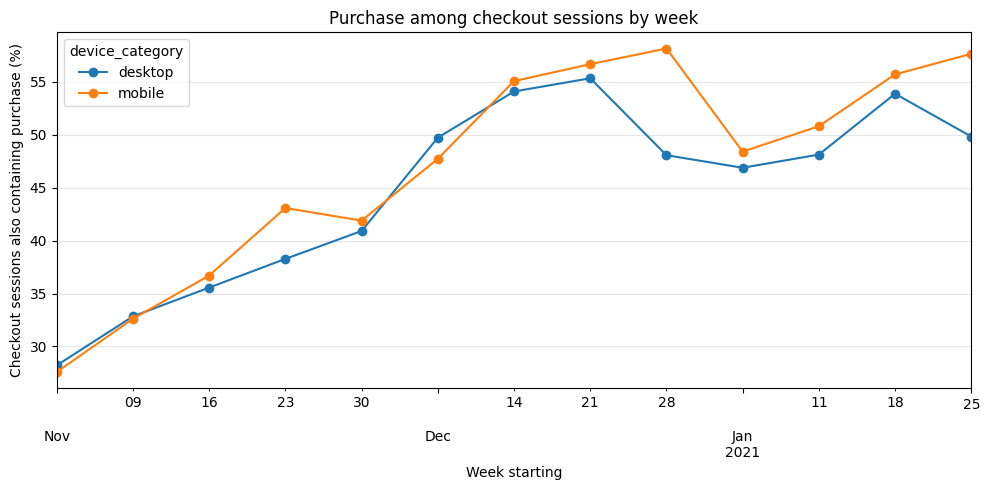

device_category,desktop,mobile
week_start,,
2020-10-26,15.517241,10.810811
2020-11-02,28.210117,27.586207
2020-11-09,32.840722,32.619048
2020-11-16,35.563380,36.703297
2020-11-23,38.274933,43.086172
2020-11-30,40.914561,41.889483
2020-12-07,49.732620,47.734628
2020-12-14,54.101222,55.082742
2020-12-21,55.348837,56.684492


In [23]:
weekly_device_checkout = (
    checkout_sessions
    .groupby(["week_start", "device_category"])
    ["purchase_session_flag"]
    .mean()
    .unstack("device_category")
    * 100
)

# Exclude the first, partial week from the chart.
ax = weekly_device_checkout.iloc[1:][["desktop", "mobile"]].plot(
    figsize=(10, 5),
    marker="o"
)

ax.set_title("Purchase among checkout sessions by week")
ax.set_xlabel("Week starting")
ax.set_ylabel("Checkout sessions also containing purchase (%)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

weekly_device_checkout

Both devices show an upward pattern. Standardize their checkout mix across weeks using **checkout session counts**, since that is this metric's denominator. This is a different weighting population from the earlier all-session adjustment.

In [24]:
weekly_checkout_counts = (
    checkout_sessions
    .groupby(["week_start", "device_category"])
    .size()
    .unstack("device_category", fill_value=0)
)

combined_checkouts = (
    weekly_checkout_counts["mobile"]
    + weekly_checkout_counts["desktop"]
)

checkout_week_weights = (
    combined_checkouts / combined_checkouts.sum()
)

adjusted_checkout_mobile_pct = (
    weekly_device_checkout["mobile"] * checkout_week_weights
).sum()

adjusted_checkout_desktop_pct = (
    weekly_device_checkout["desktop"] * checkout_week_weights
).sum()

adjusted_checkout_difference_pp = (
    adjusted_checkout_mobile_pct - adjusted_checkout_desktop_pct
)

print(
    f"Week-adjusted checkout difference: "
    f"{adjusted_checkout_difference_pp:.4f} percentage points"
)
print(
    f"Unadjusted checkout difference: "
    f"{checkout_observed_difference * 100:.4f} percentage points"
)

Week-adjusted checkout difference: 1.4364 percentage points
Unadjusted checkout difference: 1.5550 percentage points


The adjusted checkout gap is **+1.4364 pp**, versus **+1.5550 pp** unadjusted. Timing explains a small part of the observed gap, but no adjusted interval has been calculated. Shared trends do not establish a website improvement or identify its cause.

### 6.2 Missing cart events

Check whether checkout sessions contain a cart flag and then whether any cart sessions exist each week. `assign()` creates a temporary Boolean indicator; its mean is the share of checkout sessions lacking a cart event. The second table checks the broader session population.

In [25]:
checkout_tracking_by_week = (
    checkout_sessions
    .assign(
        checkout_without_cart=lambda df: df["added_to_cart"] == 0
    )
    .groupby("week_start")
    .agg(
        checkout_sessions=("purchase_session_flag", "size"),
        checkout_without_cart_pct=("checkout_without_cart", "mean"),
        purchase_among_checkout_pct=("purchase_session_flag", "mean")
    )
)

checkout_tracking_by_week[
    ["checkout_without_cart_pct", "purchase_among_checkout_pct"]
] *= 100

checkout_tracking_by_week

,checkout_sessions,checkout_without_cart_pct,purchase_among_checkout_pct
week_start,,,
2020-10-26,95,98.947368,13.684211
2020-11-02,862,100.000000,27.958237
2020-11-09,1029,100.000000,32.750243
2020-11-16,1023,75.464321,36.070381
2020-11-23,1241,54.230459,40.209508
2020-11-30,1392,18.318966,41.307471
2020-12-07,1553,21.442370,48.937540
2020-12-14,996,26.405622,54.518072
2020-12-21,402,27.114428,55.970149


In [26]:
weekly_event_check = (
    sessions[
        sessions["device_category"].isin(["mobile", "desktop"])
    ]
    .groupby("week_start")
    .agg(
        total_sessions=("purchase_session_flag", "size"),
        product_view_sessions=("viewed_product", "sum"),
        cart_sessions=("added_to_cart", "sum"),
        checkout_sessions=("began_checkout", "sum"),
        purchase_sessions=("purchase_session_flag", "sum")
    )
)

weekly_event_check["cart_reach_pct"] = (
    100
    * weekly_event_check["cart_sessions"]
    / weekly_event_check["total_sessions"]
)

weekly_event_check

,total_sessions,product_view_sessions,cart_sessions,checkout_sessions,purchase_sessions,cart_reach_pct
week_start,,,,,,
2020-10-26,2575,525,1,95,13,0.038835
2020-11-02,24434,5391,0,862,241,0.000000
2020-11-09,22001,5455,0,1029,339,0.000000
2020-11-16,25347,6486,522,1023,369,2.059415
2020-11-23,27187,6345,1210,1241,499,4.450657
2020-11-30,30388,7610,2559,1392,576,8.421087
2020-12-07,37878,8083,2667,1553,760,7.041026
2020-12-14,32695,6951,2053,996,543,6.279248
2020-12-21,21592,4017,965,402,225,4.469248


**External SQL validation:** daily raw-event queries run in BigQuery found zero mobile/desktop `add_to_cart` events on **November 2–15 and November 21–24**, while checkout and purchase events continued. This confirms the absence exists upstream of the Python/session summaries; its cause remains unknown. Cart events occurred on every day of December–January, but nonzero counts do not prove completeness.

The validation queries are included in the SQL appendix. They are not executed by this notebook. These gaps undermine full-period cart-based progression interpretation, but do not automatically invalidate every purchase or checkout observation.

<a id="ordered"></a>

## 7. December–January sensitivity period and ordered funnel

### 7.1 Restrict by session date

Retain mobile/desktop sessions from December 1 through January 31. This is a separate sensitivity population, not a replacement for the original analysis. Stage flags still indicate co-occurrence, even after dates with obvious cart gaps are excluded.

In [27]:
dec_jan_sessions = sessions[
    (sessions["session_date"] >= "2020-12-01")
    & (sessions["session_date"] < "2021-02-01")
    & sessions["device_category"].isin(["mobile", "desktop"])
].copy()

dec_jan_stage_summary = pd.DataFrame({
    "sessions_reaching_stage": dec_jan_sessions[stage_columns].sum(),
    "stage_reach_pct": dec_jan_sessions[stage_columns].mean() * 100
})

print("December–January sessions:", len(dec_jan_sessions))

dec_jan_stage_summary

December–January sessions: 246106


,sessions_reaching_stage,stage_reach_pct
viewed_product,49948,20.295320
added_to_cart,12713,5.165660
began_checkout,6378,2.591566
purchase_session_flag,3158,1.283187


In [28]:
dec_jan_checkouts = dec_jan_sessions[
    dec_jan_sessions["began_checkout"] == 1
]

without_cart = (
    dec_jan_checkouts["added_to_cart"] == 0
).sum()

with_purchase = (
    dec_jan_checkouts["purchase_session_flag"].sum()
)

print("Checkout sessions:", len(dec_jan_checkouts))
print("Checkout sessions without cart:", without_cart)
print(
    "Checkout without cart (%):",
    round(100 * without_cart / len(dec_jan_checkouts), 2)
)
print(
    "Purchase among checkout (%):",
    round(100 * with_purchase / len(dec_jan_checkouts), 2)
)

Checkout sessions: 6378
Checkout sessions without cart: 1572
Checkout without cart (%): 24.65
Purchase among checkout (%): 49.5


**Result:** 1,572 of 6,378 checkout sessions (24.65%) still lack a same-session cart flag; 49.50% contain purchase. Earlier-session carts or measurement limitations may contribute. We cannot treat every missing flag as an error or every non-purchasing session as abandonment.

### 7.2 Strict timestamp-ordered funnel

**Provenance:** the counts below were manually entered from the BigQuery query reproduced in the appendix. They are not recalculated from `Sessions.csv`, because that export does not contain event timestamps. If the SQL scope changes, rerun the SQL and update these constants.

Each user–session pair is counted once. Select the earliest view, earliest cart strictly after that view, earliest checkout strictly after that cart, and earliest purchase strictly after that checkout. Strict `>` excludes timestamp ties. The sequence does not require the same product across stages.

SQL restricts **event-table dates**, while Python restricts `session_date`. Boundary-crossing sessions can differ. For example, SQL records 49,952 view sessions versus 49,948 in the Python subset; do not force these counts to match.

In [29]:
ordered_funnel = pd.DataFrame({
    "stage": [
        "All sessions",
        "Product view",
        "View → cart",
        "View → cart → checkout",
        "View → cart → checkout → purchase"
    ],
    "sessions": [246122, 49952, 12020, 4247, 2302]
})

ordered_funnel["progression_pct"] = (
    ordered_funnel["sessions"]
    / ordered_funnel["sessions"].shift(1)
    * 100
)

ordered_funnel["sessions_not_progressing"] = (
    ordered_funnel["sessions"]
    - ordered_funnel["sessions"].shift(-1)
)

ordered_funnel

,stage,sessions,progression_pct,sessions_not_progressing
0,All sessions,246122,NaN,196170.0
1,Product view,49952,20.295626,37932.0
2,View → cart,12020,24.063101,7773.0
3,View → cart → checkout,4247,35.332779,1945.0
4,View → cart → checkout → purchase,2302,54.202967,NaN


`shift(1)` aligns each stage with its predecessor for progression rates. `shift(-1)` aligns the following stage to count sessions not progressing. The first progression rate and final non-progression count are undefined, so `NaN` is expected.

**Interpretation:** 24.06% of view sessions reach a subsequent cart; 35.33% of those ordered cart sessions reach checkout; 54.20% of those ordered checkout sessions reach purchase. The **1,945** ordered checkout sessions without subsequent purchase are not guaranteed recoverable orders. This strict funnel excludes legitimate journeys spanning multiple sessions.

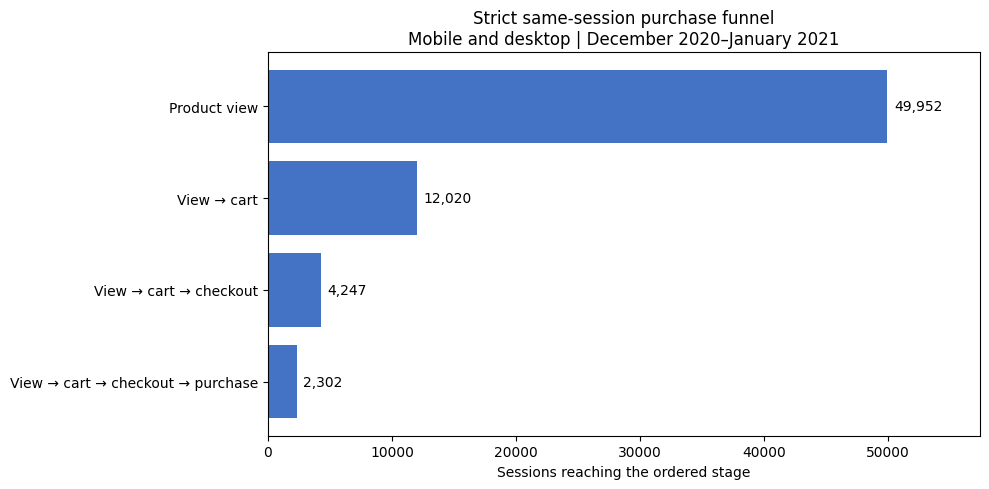

In [30]:
# Start at product view so the smaller stages remain readable.
plot_data = ordered_funnel.iloc[1:]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    plot_data["stage"],
    plot_data["sessions"],
    color="#4472C4"
)

ax.invert_yaxis()
ax.bar_label(
    bars,
    labels=[f"{n:,}" for n in plot_data["sessions"]],
    padding=5
)

ax.set_xlim(0, plot_data["sessions"].max() * 1.15)
ax.set_title(
    "Strict same-session purchase funnel\n"
    "Mobile and desktop | December 2020–January 2021"
)
ax.set_xlabel("Sessions reaching the ordered stage")

plt.tight_layout()
plt.show()

<a id="revenue"></a>

## 8. Illustrative revenue scenarios

These scenarios deliberately return to **all-period mobile/desktop checkout co-occurrence**: 10,866 checkout sessions. They do not use the 4,247 December–January ordered checkouts above.

An absolute improvement of $d$ percentage points yields $10{,}866\times d/100$ modeled additional purchasing sessions. Multiplying by AOV assumes **one additional order per additional purchasing session**.

The **$69.13 AOV** is a restricted-subset SQL estimate: $306,678 divided by 4,436 eligible orders. IDs with missing/conflicting information were excluded, and repeated records with consistent user/revenue were collapsed under an explicit assumption. It is not verified storewide AOV, nor necessarily the value of incremental checkout orders. Figures are gross revenue before costs, refunds, cannibalization, and implementation expenses.

In [31]:
scenario_summary = pd.DataFrame({
    "improvement_pp": [0.5, 1.0, 2.0]
})

scenario_summary["additional_purchasing_sessions"] = (
    total_checkout_sessions
    * scenario_summary["improvement_pp"]
    / 100
)

scenario_summary["illustrative_revenue_usd"] = (
    scenario_summary["additional_purchasing_sessions"] * 69.13
)

scenario_summary.round(2)

,improvement_pp,additional_purchasing_sessions,illustrative_revenue_usd
0,0.5,54.33,3755.83
1,1.0,108.66,7511.67
2,2.0,217.32,15023.33


A +1 pp scenario gives 108.66 modeled additional purchasing sessions and **$7,511.67** at this AOV. Fractional counts represent expected scenario quantities, not literal fractional sessions. No intervention effect has been estimated.

Vary AOV to show dependence on this input. The $50 and $90 endpoints below are illustrative alternatives, **not confidence bounds**. Historical checkout rates vary over time, so these calculations should not be treated as stable future forecasts.

In [32]:
aov_sensitivity = scenario_summary[
    ["improvement_pp", "additional_purchasing_sessions"]
].copy()

for aov in [50, 69.13, 90]:
    aov_sensitivity[f"revenue_at_aov_{aov:.2f}"] = (
        aov_sensitivity["additional_purchasing_sessions"] * aov
    )

aov_sensitivity.round(2)

,improvement_pp,additional_purchasing_sessions,revenue_at_aov_50.00,revenue_at_aov_69.13,revenue_at_aov_90.00
0,0.5,54.33,2716.5,3755.83,4889.7
1,1.0,108.66,5433.0,7511.67,9779.4
2,2.0,217.32,10866.0,15023.33,19558.8


<a id="experiment"></a>

## 9. Findings and experiment proposal

The analysis supports investigation and measurement validation, not a causal recommendation for a specific device. The following summary connects the evidence to a proposed test.

Overall conversion: 4,848 of 360,129 sessions contained a purchase, or 1.35%.

Device comparison: Mobile’s observed advantage was 0.0776 percentage points, with a user-bootstrap 95% interval of −0.0051 to +0.1610. The evidence doesn’t clearly distinguish the population difference from zero. Adjusting separately for week and first-user medium barely changed the estimate.

Measurement limitation: Raw mobile/desktop cart events were absent on November 2–15 and November 21–24, despite recorded checkouts and purchases. The cause is unknown.

Restricted ordered funnel: For December–January mobile/desktop activity, 49,952 sessions reached product view, 12,020 reached a subsequent cart, 4,247 reached a subsequent checkout, and 2,302 reached a subsequent purchase.

Business implication: Validate event collection and investigate checkout friction before recommending a device-specific redesign. The 1,945 ordered checkout sessions without a subsequent purchase identify activity to investigate, not guaranteed recoverable sales.


**Experiment proposal: Estimated delivery dates for ground shipping**

**Opportunity and supporting evidence**

During a current website review, I observed that the default ground-shipping option did not specify an estimated delivery date. This creates a potential source of uncertainty for customers deciding whether to complete a purchase.

Historical analysis of December 2020–January 2021 mobile and desktop sessions identified 4,247 sessions with an ordered product-view → cart → checkout sequence. Of these, 2,302 contained a subsequent purchase, giving a strict same-session completion rate of 54.20%.

These findings motivate investigating checkout, but they do not establish why customers failed to purchase. The current website observation and historical dataset represent different periods; the missing delivery estimate cannot be assumed to explain historical behavior.

**Hypothesis**

Displaying a credible estimated arrival-date range alongside the default ground-shipping option will increase purchase completion by reducing uncertainty about delivery timing.

**Control and treatment**

| Group | Experience |
|---|---|
| Control | Existing ground-shipping option without an estimated arrival-date range |
| Treatment | Identical option with an estimated arrival range, such as “Estimated arrival: November 3–6” |

Shipping prices, available services, actual shipping speeds, and the default selection will remain unchanged. Arrival estimates must account for destination, processing time, order cutoffs, weekends, and holidays.

**Eligibility and randomization**

Include mobile and desktop users reaching the shipping-option step whose destinations support ground shipping and a credible arrival estimate.

Randomly assign eligible users 50/50 immediately before displaying the shipping options. Maintain the same assignment across repeat visits using a persistent experiment identifier. Do not restrict the analysis to users who ultimately select ground shipping, because the treatment may affect that choice.

**Primary success metric**

The percentage of eligible randomized users who complete at least one purchase within seven days of their first eligible checkout:

\[
\text{Purchase rate}
=
\frac{\text{Randomized users purchasing within seven days}}
{\text{All eligible randomized users}}
\]

Count each user once and analyze them according to their assigned group.

**Secondary metrics and guardrails**

- Revenue per randomized user.
- Shipping-method selection, including any shift away from paid upgrades.
- Checkout errors and page performance.
- Order cancellations and delivery-related support contacts.
- For treatment orders, the share delivered outside the displayed arrival range.

Revenue measures should use deduplicated transaction records. Delivery and cancellation outcomes require follow-up beyond the purchase window.

**Sample size and duration**

Before launch, estimate the current seven-day user purchase rate using the same eligibility rules. The historical 54.20% session-based rate is not an interchangeable baseline.

Set the minimum worthwhile absolute improvement before calculating sample size, using 80% power and a two-sided 5% significance level. A one-percentage-point improvement can be evaluated as a planning scenario, but should be justified against implementation costs and expected value.

Run for the planned sample size across complete weekly cycles. Allow every enrolled user seven days of purchase follow-up. Do not stop early simply because an interim result becomes statistically significant.

**Analysis and decision**

Report the treatment-minus-control purchase-rate difference and its 95% confidence interval. Check assignment balance and event collection before interpreting results.

Recommend rollout if the evidence supports a commercially worthwhile improvement without unacceptable guardrail deterioration. If uncertainty remains large, report the result as inconclusive rather than claiming the treatment has no effect.

This experiment tests whether clearer delivery information improves purchasing behavior; it does not test faster shipping.

<a id="power"></a>

## 10. Experiment sample size and duration

### 10.1 Sensitivity to an unknown baseline

We do not have the current **seven-day user purchase rate among eligible users**. Historical session metrics (43.63%, 49.50%, or 54.20%) are not interchangeable baselines. The following calculations use explicit hypothetical baselines.

`proportion_effectsize()` converts two proportions into Cohen's $h$ (an arcsine-scale difference). `NormalIndPower.solve_power()` provides an approximate independent two-group sample size with 80% power, two-sided alpha 0.05, and equal allocation. `ceil()` rounds up to whole users. A +1 pp effect is +0.01 in proportion units.

80% power means approximately an 80% probability of rejecting the null under the specified alternative and assumptions—not an 80% probability that the hypothesis is true. Users must be independently randomized with one binary primary outcome per user.

In [33]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

power_analysis = NormalIndPower()
sample_size_rows = []

for baseline in [0.30, 0.40, 0.50, 0.60]:
    treatment_rate = baseline + 0.01

    effect_size = abs(
        proportion_effectsize(treatment_rate, baseline)
    )

    users_per_group = int(np.ceil(
        power_analysis.solve_power(
            effect_size=effect_size,
            alpha=0.05,
            power=0.80,
            ratio=1,
            alternative="two-sided"
        )
    ))

    sample_size_rows.append({
        "baseline_pct": baseline * 100,
        "treatment_pct": treatment_rate * 100,
        "users_per_group": users_per_group,
        "total_users": users_per_group * 2
    })

sample_size_summary = pd.DataFrame(sample_size_rows)

sample_size_summary

,baseline_pct,treatment_pct,users_per_group,total_users
0,30.0,31.0,33274,66548
1,40.0,41.0,37827,75654
2,50.0,51.0,39240,78480
3,60.0,61.0,37513,75026


### 10.2 Sensitivity to the detectable improvement

Hold the baseline at 50% and vary the target absolute effect. Approximately halving the detectable effect quadruples the required sample. A larger minimum detectable effect makes the test less sensitive; it does not make large benefits more likely. Choose the commercially meaningful target before launch, not to obtain a convenient duration.

In [34]:
sample_size_by_effect = []

for improvement_pp in [0.5, 1.0, 2.0, 3.0]:
    baseline = 0.50
    treatment_rate = baseline + improvement_pp / 100

    effect_size = abs(
        proportion_effectsize(treatment_rate, baseline)
    )

    users_per_group = int(np.ceil(
        power_analysis.solve_power(
            effect_size=effect_size,
            alpha=0.05,
            power=0.80,
            ratio=1,
            alternative="two-sided"
        )
    ))

    sample_size_by_effect.append({
        "improvement_pp": improvement_pp,
        "users_per_group": users_per_group,
        "total_users": users_per_group * 2
    })

pd.DataFrame(sample_size_by_effect)

,improvement_pp,users_per_group,total_users
0,0.5,156972,313944
1,1.0,39240,78480
2,2.0,9806,19612
3,3.0,4356,8712


### 10.3 Translate samples into planning timelines

Daily traffic is **new eligible users across both groups combined**, not sessions or repeat visits. Divide total users by assumed daily users, round enrollment up to whole weeks, then add seven days for the final cohort's purchase window. Delivery outcomes need longer follow-up.

These scenarios assume steady traffic and enough eligible users; very long durations are arithmetic illustrations, not recommended test plans. Current traffic must be measured before setting a launch date or duration.

In [35]:
duration_scenarios = []

for result in sample_size_by_effect:
    for daily_users in [100, 500, 1000]:
        enrollment_days = int(np.ceil(
            result["total_users"] / daily_users
        ))

        # Round enrollment up to complete weeks.
        enrollment_days = int(
            np.ceil(enrollment_days / 7) * 7
        )

        duration_scenarios.append({
            "improvement_pp": result["improvement_pp"],
            "new_eligible_users_per_day": daily_users,
            "enrollment_days": enrollment_days,
            "days_through_purchase_followup": enrollment_days + 7
        })

duration_summary = pd.DataFrame(duration_scenarios)

duration_summary

,improvement_pp,new_eligible_users_per_day,enrollment_days,days_through_purchase_followup
0,0.5,100,3143,3150
1,0.5,500,630,637
2,0.5,1000,315,322
3,1.0,100,791,798
4,1.0,500,161,168
5,1.0,1000,84,91
6,2.0,100,203,210
7,2.0,500,42,49
8,2.0,1000,21,28
9,3.0,100,91,98


**Feasibility example:** at a hypothetical 50% baseline and 500 new eligible users/day, detecting +2 pp requires 19,612 users: 42 enrollment days plus 7 follow-up days, or **49 days**. Detecting +1 pp requires 78,480 users and **168 days** including follow-up. Historical sample traffic is not a measurement of present site eligibility.

<a id="conclusion"></a>

## 11. Conclusions and next steps

1. **Validate measurement first.** Explain the raw cart-event gaps and confirm transaction deduplication and experiment event collection before relying on funnel losses.
2. **Avoid an unsupported device diagnosis.** Both unadjusted device intervals include zero; separate standardizations barely change the overall point estimate.
3. **Use the restricted funnel honestly.** It describes recorded, strictly ordered same-session activity and excludes other valid paths.
4. **Test a concrete hypothesis.** The current site review identifies missing ground-shipping arrival dates; it does not establish the cause of historical behavior.
5. **Confirm feasibility before launch.** Measure the current eligible-user baseline and enrollment volume, choose a worthwhile effect size, and predefine guardrail tolerances and the fixed-horizon decision rule.

### Reproducibility and limitations

- Existing code and saved outputs are retained; code cells follow their dependencies. Execution counts reflect the original run history.
- The CSV is an external prerequisite, not embedded in this notebook. The SQL-derived funnel and AOV are documented external inputs.
- The source is historical and obfuscated; user identifiers may not correspond one-to-one with people, and causal interpretation is not warranted.
- Bootstrapping models sampling variation under user-cluster assumptions; it cannot fix systematic measurement problems.
- Week and medium adjustments are separate point-estimate sensitivity checks, not a joint causal model.
- Interpretive text describes the saved results and should be refreshed if the dataset or methods change.

<a id="sql"></a>

## 12. SQL provenance and reproducibility

Run these queries in BigQuery, not as Python cells. The source is `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`.

### Daily raw-event coverage audit

This reproduces the coverage check across the complete period. It counts events, not sessions, so repeated events can increase totals.

```sql
SELECT
  PARSE_DATE('%Y%m%d', event_date) AS event_day,
  COUNTIF(event_name = 'view_item') AS product_view_events,
  COUNTIF(event_name = 'add_to_cart') AS cart_events,
  COUNTIF(event_name = 'begin_checkout') AS checkout_events,
  COUNTIF(event_name = 'purchase') AS purchase_events
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
WHERE _TABLE_SUFFIX BETWEEN '20201101' AND '20210131'
  AND device.category IN ('mobile', 'desktop')
GROUP BY event_day
ORDER BY event_day;
```

### December–January strict ordered funnel

This implements the query used for the manually entered funnel totals. The earliest qualifying event at each stage determines whether a complete chain exists; sessions with repeated chains are still counted once.

```sql
WITH extracted_events AS (
  SELECT user_pseudo_id,
    (SELECT ep.value.int_value FROM UNNEST(event_params) AS ep
     WHERE ep.key = 'ga_session_id') AS ga_session_id,
    event_name, event_timestamp
  FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
  WHERE _TABLE_SUFFIX BETWEEN '20201201' AND '20210131'
    AND device.category IN ('mobile', 'desktop')
), first_views AS (
  SELECT user_pseudo_id, ga_session_id,
    MIN(CASE WHEN event_name = 'view_item' THEN event_timestamp END) AS view_timestamp
  FROM extracted_events
  WHERE user_pseudo_id IS NOT NULL AND ga_session_id IS NOT NULL
  GROUP BY user_pseudo_id, ga_session_id
), ordered_carts AS (
  SELECT v.user_pseudo_id, v.ga_session_id, v.view_timestamp,
    MIN(e.event_timestamp) AS cart_timestamp
  FROM first_views AS v
  LEFT JOIN extracted_events AS e
    ON v.user_pseudo_id = e.user_pseudo_id AND v.ga_session_id = e.ga_session_id
    AND e.event_name = 'add_to_cart' AND e.event_timestamp > v.view_timestamp
  GROUP BY v.user_pseudo_id, v.ga_session_id, v.view_timestamp
), ordered_checkouts AS (
  SELECT c.user_pseudo_id, c.ga_session_id, c.view_timestamp, c.cart_timestamp,
    MIN(e.event_timestamp) AS checkout_timestamp
  FROM ordered_carts AS c
  LEFT JOIN extracted_events AS e
    ON c.user_pseudo_id = e.user_pseudo_id AND c.ga_session_id = e.ga_session_id
    AND e.event_name = 'begin_checkout' AND e.event_timestamp > c.cart_timestamp
  GROUP BY c.user_pseudo_id, c.ga_session_id, c.view_timestamp, c.cart_timestamp
), ordered_purchases AS (
  SELECT ch.user_pseudo_id, ch.ga_session_id, ch.view_timestamp,
    ch.cart_timestamp, ch.checkout_timestamp,
    MIN(e.event_timestamp) AS purchase_timestamp
  FROM ordered_checkouts AS ch
  LEFT JOIN extracted_events AS e
    ON ch.user_pseudo_id = e.user_pseudo_id AND ch.ga_session_id = e.ga_session_id
    AND e.event_name = 'purchase' AND e.event_timestamp > ch.checkout_timestamp
  GROUP BY ch.user_pseudo_id, ch.ga_session_id, ch.view_timestamp,
    ch.cart_timestamp, ch.checkout_timestamp
)
SELECT COUNT(*) AS total_sessions,
  COUNTIF(view_timestamp IS NOT NULL) AS viewed_product,
  COUNTIF(cart_timestamp IS NOT NULL) AS viewed_then_cart,
  COUNTIF(checkout_timestamp IS NOT NULL) AS viewed_cart_then_checkout,
  COUNTIF(purchase_timestamp IS NOT NULL) AS completed_full_funnel
FROM ordered_purchases;
```